# 2. Exploration

We now look at the signals themselves, on the north cable first. You will:
1. convert the data to physical units,
2. compare three parts of the cable: on land, in shallow water and during the earthquake,
3. remove the noise common to all channels,
4. find where the earthquake energy lies with an FK transform, and keep only that part,
5. convert the record to displacement,
6. pick the first arrival with an STA/LTA detector,
7. locate the earthquake and estimate its magnitude, with both cables,
8. estimate the magnitude from the P wave alone, as an early-warning system must.

On the way, you will write a few small functions. Notebook 3 reuses them.

In [1]:
# solutions only: run from the exercises folder
%cd ..

/Users/trabatto/pkgs/exercises


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as sp
import xdas as xd

from xdas.picking import tapered_selection

from tools import distance_km, locate

Start from the collection saved in notebook 1 (with the cable geometry).

In [3]:
abyss = xd.open("abyss.nc")
da = abyss["N"]
da

<xdas.DataArray (time: 24000, distance: 6664)>
VirtualSource: 610.1MB (float32)
Coordinates:
  * distance (distance): 0.000 to 102073.848
  * time (time): 2024-09-02T02:55:06.000 to 2024-09-02T02:59:05.990
    latitude (distance): [-29.89263556 ... -29.23606618]
    longitude (distance): [-71.25330943 ... -71.72586396]
    depth (distance): [   0.  ... 1339.1]

## Physical units

The interrogator measures how fast the phase of the backscattered light changes, per meter of
fiber: the unit is rad/(s·m). Straining the fiber at a rate $\dot\varepsilon$ makes it change by

$$\frac{\partial^2\phi}{\partial x \, \partial t} = \frac{4 \pi n \xi}{\lambda} \, \dot\varepsilon$$

with $\lambda$ the laser wavelength, $n$ the refractive index of the fiber and $\xi$ the
photoelastic factor of silica.

**Task:** compute the `gain` that converts the data from rad/(s·m) to strain rate (1/s).

| | value |
|---|---|
| $\lambda$ | 1536.6 nm |
| $n$ | 1.4677 |
| $\xi$ | 0.78 |

The interrogator stores the inverse of your result in its files (`header/sensitivities`):
9 362 208.9 rad/(strain·m).

In [4]:
wavelength = 1536.6e-9  # m
n = 1.4677
xi = 0.78
gain = wavelength / (4 * np.pi * n * xi)
gain

1.0681175917797704e-07

## Three parts of the cable

The first ~4.5 km of the cable are on land. Then the cable enters the sea and goes down to
~1500 m (look at `da["depth"]`). The earthquake arrives around 02:56:15.

**Task:** cut three tiles, load them and convert them to strain rate:
- **land**: 0–4.5 km, from 02:57:00 to the end;
- **shallow water**: 5–10 km, from 02:57:00 to 02:58:00;
- **earthquake**: 20–90 km, from 02:56:10 to 02:56:40.

Which signals do you see on each tile?

> **Reminder:** `.sel` selects by coordinate value, `slice(start, end)` includes both ends.
> Times are written as strings. `.load()` reads the values into memory.
> ```python
> da.sel(distance=slice(1000, 2000), time=slice("2024-01-01T00:00:00", "2024-01-01T00:00:10"))
> ```

📖 [Indexing](https://xdas.readthedocs.io/en/stable/user-guide/data-structures/dataarray.html)

In [5]:
tiles = {
    "land": da.sel(distance=slice(0, 4500), time=slice("2024-09-02T02:57:00", None)),
    "shallow water": da.sel(distance=slice(5000, 10000), time=slice("2024-09-02T02:57:00", "2024-09-02T02:58:00")),
    "earthquake": da.sel(distance=slice(20000, 90000), time=slice("2024-09-02T02:56:10", "2024-09-02T02:56:40")),
}
tiles = {name: tile.load() * gain for name, tile in tiles.items()}

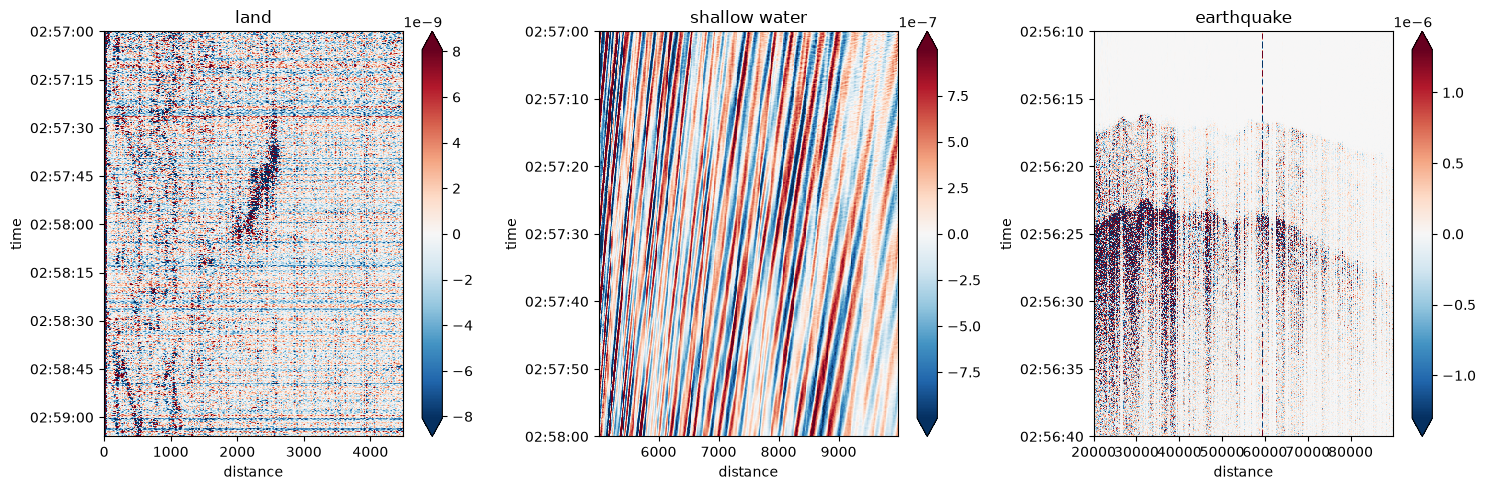

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, tile) in zip(axes, tiles.items()):
    tile.plot(ax=ax, robust=True, yincrease=False)
    ax.set_title(name)
fig.tight_layout()

## Common mode

Part of the noise is the same on every channel at the same instant: it comes from the
interrogator (its laser), not from the ground. No real wave covers 90 km of cable at once, so
what all the channels share at a given time is noise. Its estimate is the median over the
channels, which can then be subtracted from each channel.

This is plain arithmetic: a `DataArray` computes like a numpy array, and keeps its coordinates
along the way.

**Task:** complete `remove_common_mode`, which subtracts from each channel the median over all
channels at the same time.

> **Reminder:**
> ```python
> da * 2, da + db, np.abs(da)   # element by element, as with numpy arrays
> da.median("x")                # median along "x": "x" disappears, one value per remaining coordinate
> da - da.mean("x")             # the mean is repeated along "x" to match da (broadcasting)
> ```

📖 [Broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html)

In [7]:
def remove_common_mode(da):
    return da - da.median("distance")

Thirty seconds before the earthquake, from 5 to 97 km: the raw data, what is left after the
removal, and what was removed. Look for horizontal stripes.

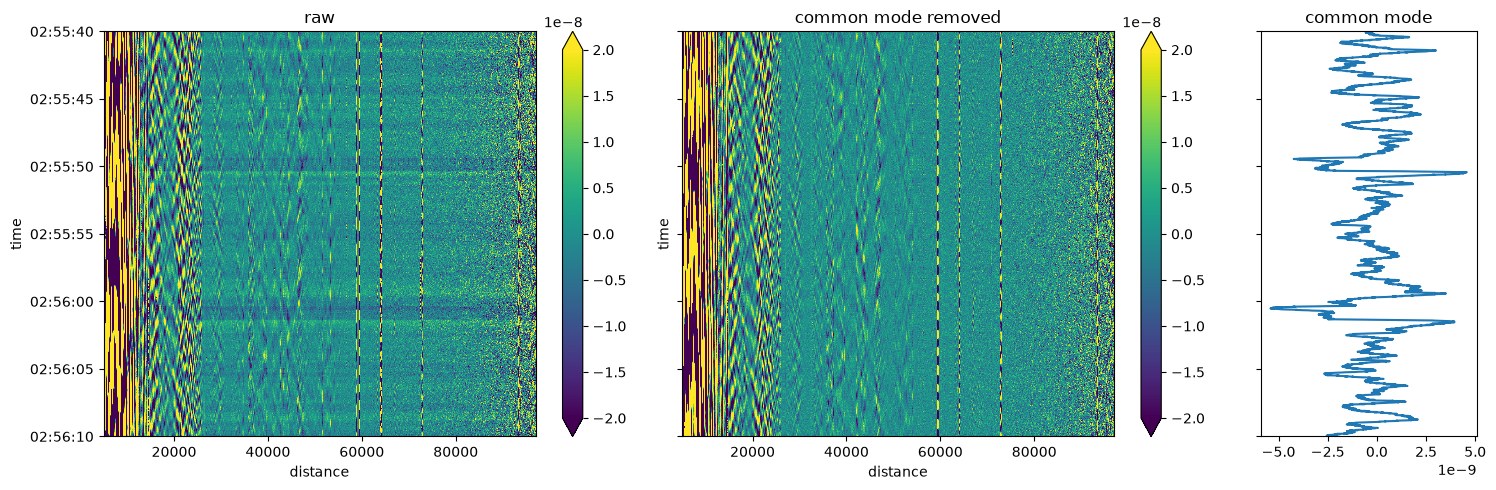

In [8]:
quiet = da.sel(time=slice("2024-09-02T02:55:40", "2024-09-02T02:56:10"), distance=slice(5000, 97000)).load() * gain
cleaned = remove_common_mode(quiet)
common = (quiet - cleaned)[:, 0]  # what was removed: the same on every channel

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, width_ratios=[1, 1, 0.4])
quiet.plot(ax=axes[0], vmin=-2e-8, vmax=2e-8, cmap="viridis", yincrease=False)
cleaned.plot(ax=axes[1], vmin=-2e-8, vmax=2e-8, cmap="viridis", yincrease=False)
axes[2].plot(common.values, common["time"].values)
axes[0].set_title("raw")
axes[1].set_title("common mode removed")
axes[2].set_title("common mode")
fig.tight_layout()

## FK analysis

A 2D Fourier transform, in time and in distance, splits a tile into plane waves. Each wave
lands at a frequency $f$ (Hz) and a wavenumber $k$ (1/m), and its apparent speed along the
cable is $v = f / k$: waves of the same speed lie on a line through the origin.

**Task:** complete `compute_fk`, in this order:
1. taper along `time`, then along `distance` (given): the edges of the tile are brought
   smoothly to 0, so that the cut does not show up as artefacts in the spectrum;
2. real FFT along `time`, which becomes `frequency`: the data are real, so negative frequencies
   would only repeat the positive ones;
3. complex FFT along `distance`, which becomes `wavenumber`: after step 2 the data are complex,
   and the sign of $k$ tells in which direction the wave travels along the cable;
4. return the amplitude in dB, $20 \log_{10} |\cdot|$.

> **Reminder:**
> ```python
> xd.taper(da, dim="x")                    # smooth window that goes to 0 at both ends of "x"
> xd.fft.rfft(da, dim={"x": "f"})          # real FFT: "x" becomes "f"; xd.fft.fft for a complex FFT
> ```

📖 [`xdas.fft`](https://xdas.readthedocs.io/en/stable/api/fft.html)

In [9]:
def compute_fk(da):
    da = xd.taper(da, dim="time")
    da = xd.taper(da, dim="distance")
    da = xd.fft.rfft(da, dim={"time": "frequency"})
    da = xd.fft.fft(da, dim={"distance": "wavenumber"})
    return 20 * np.log10(np.abs(da))

**Task:** plot the FK of each tile. The dashed lines are the speed of sound in water
(1500 m/s) and a typical P-wave speed in the crust (6000 m/s). The shallow-water energy lies at
low frequencies and wavenumbers: zoom in up to 5 Hz and 0.01 1/m.

Where is the energy of each tile? Which frequencies and wavenumbers should we keep for the
earthquake?

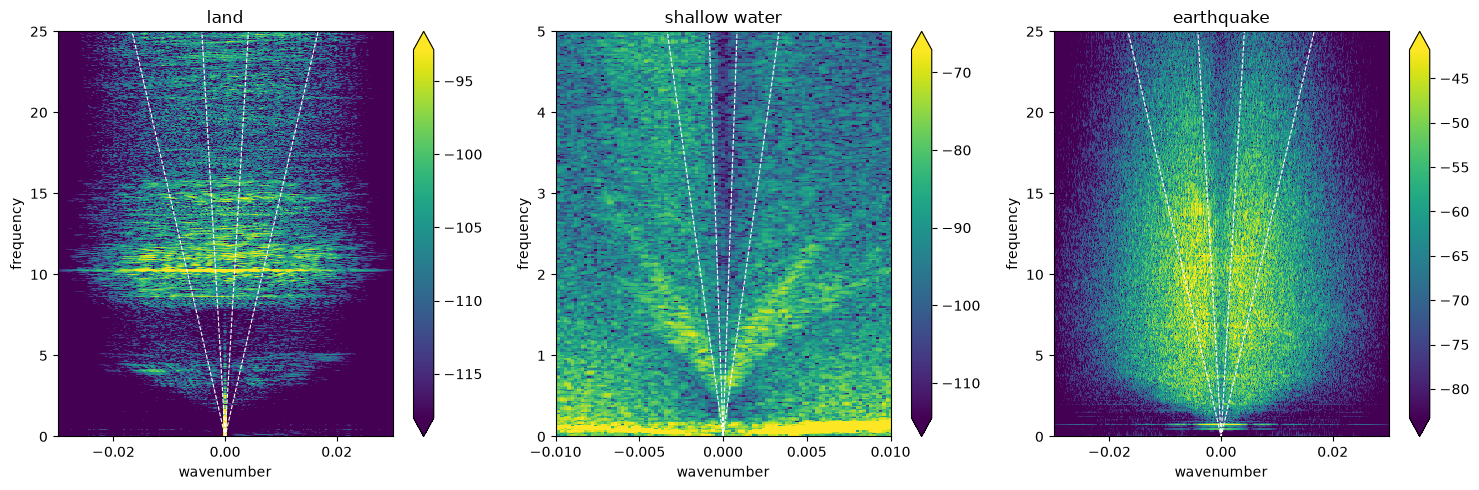

In [10]:
def plot_fk(fk, ax, fmax=25, kmax=0.03):
    vmin, vmax = np.percentile(fk.values, [50, 99.9])
    fk.plot(ax=ax, vmin=vmin, vmax=vmax)
    k = fk["wavenumber"].values
    for velocity in [1500, 6000]:
        ax.plot(k, velocity * np.abs(k), "w--", linewidth=0.8)
    ax.set_xlim(-kmax, kmax)
    ax.locator_params(axis="x", nbins=4)
    ax.set_ylim(0, fmax)


limits = {"land": (25, 0.03), "shallow water": (5, 0.01), "earthquake": (25, 0.03)}
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, tile) in zip(axes, tiles.items()):
    fk = compute_fk(tile)
    plot_fk(fk, ax, *limits[name])
    ax.set_title(name)
fig.tight_layout()

## Filter and resample

The earthquake energy lies between 2 and 15 Hz, and below 0.01 1/m in wavenumber (waves
slower than ~200 m/s along the cable are noise). Two operations keep this box:
- a **band-pass filter in time**, 2–15 Hz: it removes, among others, the slow ocean waves seen
  in shallow water;
- a **resampling in distance** to one channel every ~45 m. The Nyquist wavenumber becomes
  1 / (2 × 45 m) ≈ 0.011 1/m. Before dropping channels, `resample` low-passes the data below
  this wavenumber, or the shorter waves would fold back as aliases: it filters in distance
  for us, and leaves three times fewer channels.

**Task:** complete `preprocess`: convert to strain rate and remove the common mode (given), then
band-pass 2–15 Hz in time, then resample to ~45 m in distance.

> **Reminder:**
> ```python
> xd.filter(da, (1.0, 5.0), dim="x")      # band-pass between 1 and 5 (Hz if "x" is time)
> xd.filter(da, (None, 5.0), dim="x")     # low-pass below 5
> xd.filter(da, (1.0, None), dim="x")     # high-pass above 1
> xd.resample(da, interval=5.0, snap=True, dim="x")     # new sampling interval: ~5, keeping
>                                                       # existing samples (here one out of n)
> ```

📖 [`xdas.filter`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.filter.html) ·
[`xdas.resample`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.resample.html)

In [11]:
def preprocess(da):
    da = remove_common_mode(da * gain)
    da = xd.filter(da, (2.0, 15.0), dim="time")
    da = xd.resample(da, interval=45.0, snap=True, dim="distance")
    return da

Apply it to one minute around the earthquake, from 5 km (the cable is in the sea, still
shallow) to 97 km (the last channels are dead).

In [12]:
event = da.sel(time=slice("2024-09-02T02:56:00", "2024-09-02T02:57:00"), distance=slice(5000, 97000)).load()
processed = preprocess(event)
processed

<xdas.DataArray (time: 6001, distance: 2002)>
[[ 5.268615e-09  2.703472e-09 -7.309330e-09 ... -8.111865e-11
   1.612254e-10 -1.255519e-11]
 [ 3.423796e-08  1.753542e-08 -4.757271e-08 ... -3.228557e-10
   9.819903e-10  2.713035e-11]
 [ 1.015843e-07  5.181437e-08 -1.412525e-07 ... -3.066799e-10
   2.813054e-09  4.538188e-10]
 ...
 [-1.964494e-08 -9.450046e-09  3.126588e-08 ... -5.089074e-08
  -2.579471e-08 -3.061788e-08]
 [-1.979958e-08 -8.881057e-09  4.645149e-08 ... -6.795122e-08
  -4.409235e-08 -1.502719e-08]
 [-1.653406e-08 -9.218640e-09  5.309437e-08 ... -7.669408e-08
  -6.011514e-08 -8.893656e-09]]
Coordinates:
  * distance (distance): 5009.477 to 96972.453
  * time (time): 2024-09-02T02:56:00.000 to 2024-09-02T02:57:00.000
    latitude (distance): [-29.88806179 ... -29.28069609]
    longitude (distance): [-71.27829776 ... -71.73284248]
    depth (distance): [   5.8 ... 1527.1]

Before and after, the FK (the red box is what we keep) and the whole minute. What happened
to the slow waves of the first kilometres?

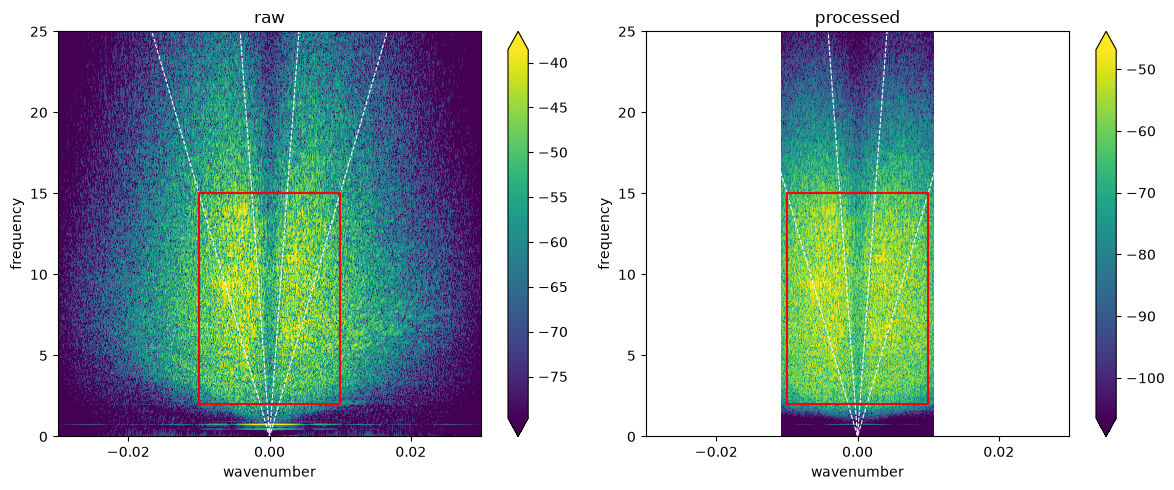

In [13]:
window = slice("2024-09-02T02:56:10", "2024-09-02T02:56:40")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title in zip(axes, [event * gain, processed], ["raw", "processed"]):
    plot_fk(compute_fk(data.sel(time=window)), ax)
    ax.plot([-0.01, 0.01, 0.01, -0.01, -0.01], [2, 2, 15, 15, 2], "r")
    ax.set_title(title)
fig.tight_layout()

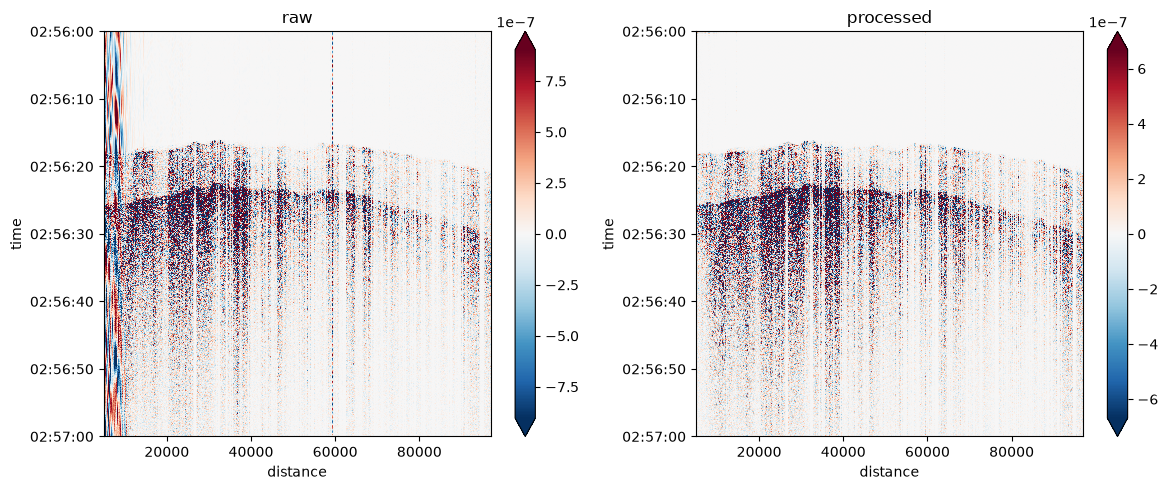

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
(event * gain)[::2, ::3].plot(ax=axes[0], robust=True, yincrease=False)  # one sample out of 2 × 3: lighter to draw
processed.plot(ax=axes[1], robust=True, yincrease=False)
axes[0].set_title("raw")
axes[1].set_title("processed")
fig.tight_layout()

## Convert to displacement

The data are still strain rate. Integrating twice gives the displacement along the cable: the
ground motion itself, that seismologists are used to read. The picker and the magnitude will
both work on it.
- integrating in time turns strain rate into strain;
- integrating strain along the cable gives the displacement along the cable, up to a constant
  that changes slowly with distance: remove it with a sliding mean of 2 km.

**Task:** complete `to_displacement` with these three steps.

> **Reminder:**
> ```python
> xd.integrate(da, dim="x")                         # cumulative integral along "x"
> xd.sliding_mean_removal(da, wlen=100.0, dim="x")  # remove the mean over a sliding window
> ```

📖 [Convert to displacement](https://xdas.readthedocs.io/en/stable/user-guide/how-to/convert-displacement.html)

In [15]:
def to_displacement(da):
    strain = xd.integrate(da, dim="time")
    displacement = xd.integrate(strain, dim="distance")
    return xd.sliding_mean_removal(displacement, wlen=2000.0, dim="distance")

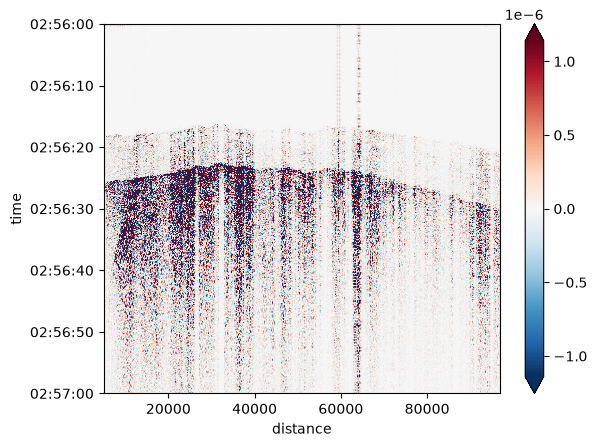

In [16]:
displacement = to_displacement(processed)
displacement.plot(robust=True, yincrease=False)

## Picking with STA/LTA

The STA/LTA detector compares the short-term average (STA) of the signal energy with its
long-term average (LTA). On noise, the ratio stays around 1. When a wave arrives, the STA
rises first and the ratio jumps.

We use the recursive form: each new sample updates the averages, with no window to keep in
memory. For the energy $x_k^2$ and a duration $T$ (s) sampled every $\Delta t$:

$$a_k = c\, x_k^2 + (1 - c)\, a_{k-1}, \qquad c = \Delta t / T$$

Moving $a_{k-1}$ to the left gives $a_k + (c - 1)\, a_{k-1} = c\, x_k^2$: this is a filter,
that `sp.lfilter` computes with the coefficients `b = [c]` and `a = [1, c - 1]`.

**Task:** complete `stalta`, step by step:
1. `power`: the energy, i.e. the values of `da` squared (as a numpy array);
2. `short`: the recursion on `power` along time (axis 0), with `c = csta`;
3. `long`: the same, with `c = clta`;
4. `ratio`: the short average divided by the long one.

The rest is given: the first `lta` seconds are set to 0 (the long average is still building
up), and the ratio is put back into a `DataArray`.

> **Reminder:** `sp.lfilter(b, a, x, axis=0)` computes, along the first axis,
> `a[0] y[k] + a[1] y[k-1] = b[0] x[k]`. `da.values` gives the numpy array of a `DataArray`, and
> `da.copy(data=x)` puts a new array back with the same coordinates.

In [17]:
def stalta(da, sta, lta):
    dt = da["time"].get_sampling_interval()
    csta, clta = dt / sta, dt / lta
    power = da.values ** 2
    short = sp.lfilter([csta], [1, csta - 1], power, axis=0)
    long = sp.lfilter([clta], [1, clta - 1], power, axis=0)
    ratio = short / long
    ratio[: round(lta / dt)] = 0  # the long average is not settled yet
    return da.copy(data=ratio)

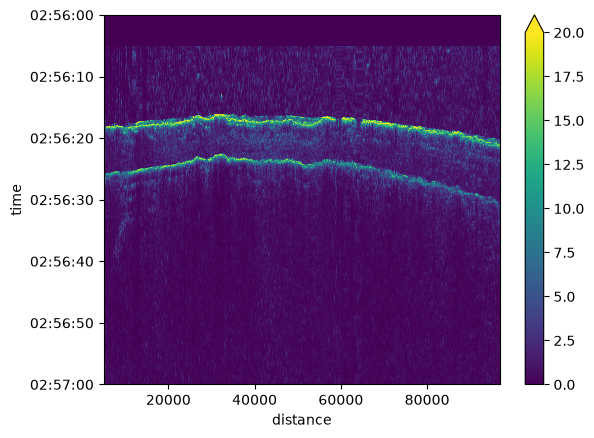

In [18]:
ratio = stalta(displacement, sta=0.2, lta=5.0)
ratio.plot(vmin=0, vmax=20, yincrease=False)

`xd.trigger` turns the ratio into picks: a trigger opens when the ratio goes above a
threshold and closes when it falls below half of it; each trigger gives one pick, at its
maximum. The first pick of each channel is the P wave.

**Task:** complete `pick`: trigger on `ratio`, keeping the coordinates needed to locate the
earthquake. The second line, given, keeps the first pick of each channel.

> **Reminder:**
> ```python
> xd.trigger(da, thresh=3.0, coords=["x", "time"])  # a pandas table, one row per pick,
>                                                   # one column per coordinate
> ```

📖 [`xdas.trigger`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.trigger.html)

In [19]:
def pick(ratio, threshold):
    picks = xd.trigger(ratio, thresh=threshold, coords=["distance", "longitude", "latitude", "depth", "time"])
    return picks.sort_values("time").groupby("distance", as_index=False).first()

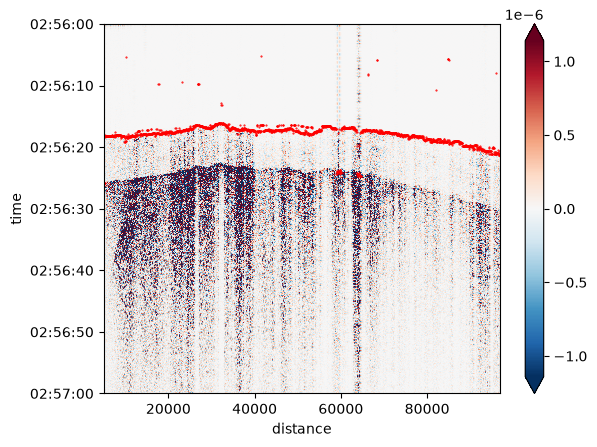

In [20]:
picks = pick(ratio, threshold=8.0)
displacement.plot(robust=True, yincrease=False)
plt.plot(picks["distance"], picks["time"], "r.", markersize=1)

## Both cables

**Task:** run the whole chain on both cables: cut one minute around the earthquake (in the sea,
without the dead channels), preprocess, convert to displacement and pick. Keep the
displacement (`records`) and the picks (`tables`) of each cable for later.

> **Reminder:** `pd.concat(list_of_dataframes, ignore_index=True)` stacks tables.

In [21]:
keep = {"N": slice(5000, 97000), "S": slice(5000, 130000)}

records, tables = {}, {}
for cable in abyss:
    event = abyss[cable].sel(time=slice("2024-09-02T02:56:00", "2024-09-02T02:57:00"), distance=keep[cable]).load()
    records[cable] = to_displacement(preprocess(event))
    tables[cable] = pick(stalta(records[cable], sta=0.2, lta=5.0), threshold=8.0)
picks = pd.concat(tables.values(), ignore_index=True)
picks

,distance,longitude,latitude,depth,time,value
0,5009.477436,-71.278298,-29.888062,5.8,2024-09-02 02:56:25.880,18.173746
1,5055.435944,-71.278752,-29.887957,6.2,2024-09-02 02:56:25.880,16.458014
2,5101.394453,-71.279206,-29.887853,6.6,2024-09-02 02:56:25.870,15.789782
3,5147.352962,-71.279661,-29.887748,7.1,2024-09-02 02:56:25.910,11.551247
4,5193.311470,-71.280116,-29.887643,7.5,2024-09-02 02:56:25.860,14.635982
...,...,...,...,...,...,...
4715,129786.828244,-71.842512,-30.718021,1545.7,2024-09-02 02:56:21.744,11.487031
4716,129832.786752,-71.842553,-30.718425,1543.3,2024-09-02 02:56:21.744,14.632785
4717,129878.745261,-71.842594,-30.718829,1540.9,2024-09-02 02:56:21.984,10.337170
4718,129924.703769,-71.842635,-30.719234,1538.5,2024-09-02 02:56:21.920,10.248992


## Location

`locate` (in `tools.py`, read it if you are curious) tries every point of a grid, one every
~5 km. For each point, every pick gives an origin time (pick time minus travel time at
7 km/s). At the right place, all these origin times agree: `locate` keeps the point where they
agree best.

Compare with the EMSC location: 71.800°W, 29.954°S, 50 km deep, 02:56:07.37.

In [22]:
location = locate(picks)
location

longitude                            -71.9
latitude                            -29.95
depth                              45000.0
time         2024-09-02 02:56:07.919999999
dtype: object

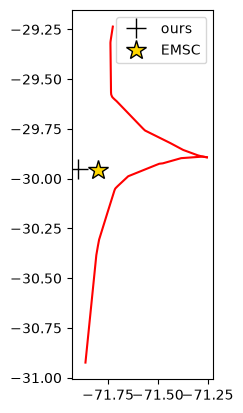

In [23]:
for cable in abyss:
    plt.plot(abyss[cable]["longitude"], abyss[cable]["latitude"], color="red")
plt.plot(location["longitude"], location["latitude"], "k+", markersize=15, label="ours")
plt.plot(-71.800, -29.954, "*", color="gold", markeredgecolor="k", markersize=15, label="EMSC")
plt.gca().set_aspect("equal")
plt.legend()

## Magnitude

The local magnitude ML was defined on the Wood–Anderson seismometer, which records ground
displacement. Its response is a high-pass filter at 1.25 Hz: above ~3 Hz it records the
displacement as it is (gain 1 in the IASPEI standard). Our displacement is band-passed to
2–15 Hz: it is already almost what a Wood–Anderson would show (within 15 %), so we use it as is.

The IASPEI formula for California (Hutton & Boore 1987):

$$M_L = \log_{10} A + 1.11 \log_{10} R + 0.00189\, R - 2.09$$

with $A$ the peak Wood–Anderson amplitude in nm and $R$ the hypocentral distance in km. Each
channel gives one estimate.

**Task:** complete `hypocentral_distance` (from the location to every channel of `da`) and
`local_magnitude`, then compute the magnitude of each channel, for each cable.

> **Reminder:** `distance_km(longitude1, latitude1, longitude2, latitude2)` (in `tools.py`)
> gives the distance in km along the Earth's surface; any of the arguments can be an array.
> The hypocentral distance adds the depth difference: $R = \sqrt{d^2 + \Delta z^2}$.
> `np.abs(x).max(axis=0)` is the peak of each column.

In [24]:
def hypocentral_distance(location, da):
    d = distance_km(location["longitude"], location["latitude"], da["longitude"].values, da["latitude"].values)
    return np.sqrt(d**2 + ((da["depth"].values - location["depth"]) / 1000) ** 2)


def local_magnitude(A, R):
    return np.log10(A) + 1.11 * np.log10(R) + 0.00189 * R - 2.09


magnitudes = {}
for cable, displacement in records.items():
    R = hypocentral_distance(location, displacement)
    A = np.abs(displacement.values).max(axis=0) * 1e9  # nm
    magnitudes[cable] = local_magnitude(A, R)

Each channel gives its own estimate. How do they compare with the catalog (EMSC: ML 3.4)?

**Task:** for each cable, and for both together, compute the number of estimates, the mean,
the standard deviation, the median and the 5–95 % range. Then plot the histogram of each
cable, with its median and the EMSC value. Is the catalog value within the spread? Do the two cables agree?

> **Reminder:**
> ```python
> pd.Series(x).describe(percentiles=[0.05, 0.5, 0.95])    # count, mean, std, min, percentiles, max
> pd.DataFrame({"a": series_a, "b": series_b})            # a table, one column per series
> np.concatenate([x, y])                                  # arrays end to end
> plt.hist(x, bins=50, alpha=0.5, color="C0", label="x")  # a histogram, half transparent
> plt.axvline(np.median(x), color="C0")                   # a vertical line, same color
> ```

In [25]:
stats = {cable: pd.Series(m).describe(percentiles=[0.05, 0.5, 0.95]) for cable, m in magnitudes.items()}
stats["both"] = pd.Series(np.concatenate(list(magnitudes.values()))).describe(percentiles=[0.05, 0.5, 0.95])
pd.DataFrame(stats)

,N,S,both
count,2002.000000,2720.000000,4722.000000
mean,3.563638,3.590597,3.579167
std,0.379605,0.293057,0.332742
min,2.619313,2.565344,2.565344
5%,2.958812,3.060761,3.008508
50%,3.534609,3.617363,3.595974
95%,4.211834,4.030739,4.097999
max,4.635250,4.366662,4.635250


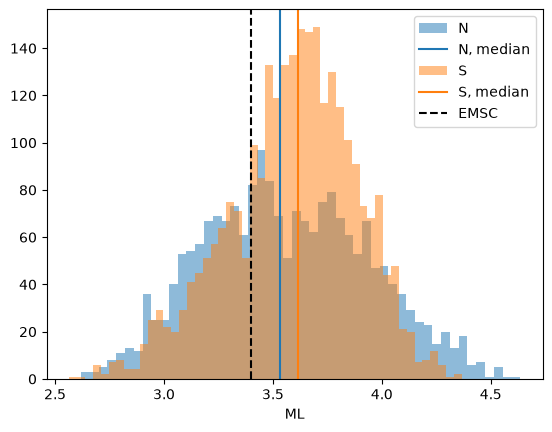

In [26]:
for (cable, m), color in zip(magnitudes.items(), ["C0", "C1"]):
    plt.hist(m, bins=50, alpha=0.5, color=color, label=cable)
    plt.axvline(np.median(m), color=color, label=f"{cable}, median")
plt.axvline(3.4, color="k", linestyle="--", label="EMSC")
plt.xlabel("ML")
plt.legend()

## Magnitude from the P wave

The peak amplitude is the S wave's, but here it comes ~7 s after the P wave, and later still
far from the earthquake. An early-warning system cannot wait for it: it sizes the earthquake
from the first seconds of the P wave, and predicts how strong the S wave will be.

**A simplified theory.** Far from a point source, the displacement carried by a wave of speed
$c$ scales as $1 / (\rho c^3)$ (Aki & Richards, 2002, eq. 4.32). The P and S waves leave the
same source and reach the same channel, so their amplitude ratio is

$$\frac{A_S}{A_P} \approx \left(\frac{V_P}{V_S}\right)^3 \frac{\mathcal{R}_S}{\mathcal{R}_P} \approx (\sqrt{3})^3 \times \frac{0.63}{0.52} \approx 6$$

with $V_P / V_S \approx \sqrt{3}$ in the crust, and $\mathcal{R}_P$, $\mathcal{R}_S$ the
radiation patterns of the fault, averaged over all directions. This ignores attenuation
(stronger on S), the sea floor, and that the fiber only feels the motion along the cable.

**Task:** measure the S/P ratio of every picked channel. For each cable, keep the first pick
of each channel and select the 2 s of displacement after it with `tapered_selection` (the S
wave never comes that early): its peak is the P peak. The S peak is the peak of the whole
minute. How does the measured ratio compare with the theory?

> **Reminder:**
> ```python
> first = table.groupby("distance")["time"].min()  # the first pick of each channel (index: distance)
> da.sel(distance=first.index)                      # the picked channels, in the same order
> tapered_selection(da, start, end, dim="time")     # for each channel, from its start to its end
> np.abs(da).max("time").values                     # the peak of each channel
> np.timedelta64(2, "s")                            # a duration
> ```

📖 [`xdas.picking.tapered_selection`](https://xdas.readthedocs.io/en/stable/_autosummary/xdas.picking.tapered_selection.html)

np.float64(7.072979740138413)

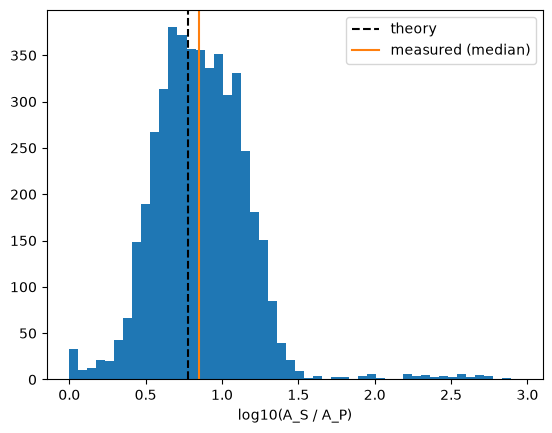

In [27]:
duration = np.timedelta64(2, "s")
peaks_p, distances, ratio = {}, {}, []
for cable, displacement in records.items():
    first = tables[cable].groupby("distance")["time"].min()
    picked = displacement.sel(distance=first.index)
    p_wave = tapered_selection(picked, first.values, first.values + duration, dim="time")
    peaks_p[cable] = np.abs(p_wave).max("time").values * 1e9  # nm
    peaks_s = np.abs(picked).max("time").values * 1e9  # nm
    ratio.append(peaks_s / peaks_p[cable])
    distances[cable] = hypocentral_distance(location, picked)
ratio = np.concatenate(ratio)

plt.hist(np.log10(ratio), bins=50)
plt.axvline(np.log10(6.0), color="k", linestyle="--", label="theory")
plt.axvline(np.log10(np.median(ratio)), color="C1", label="measured (median)")
plt.xlabel("log10(A_S / A_P)")
plt.legend()
np.median(ratio)

Why does the ratio spread so much from channel to channel? If the theory holds well enough,
an early-warning system needs no calibration: it takes the S amplitude as 6 times the P one.

**Task:** compute the magnitude of each channel from its P peak alone, with $A_S = 6 A_P$.
Compare with the magnitude from the S wave and with EMSC (ML 3.4): the statistics, and the
histograms with their medians.

,S wave,P wave
count,4722.000000,4720.000000
mean,3.579167,3.492683
std,0.332742,0.419224
min,2.565344,1.220520
5%,3.008508,2.812440
50%,3.595974,3.539536
95%,4.097999,4.069685
max,4.635250,4.867955


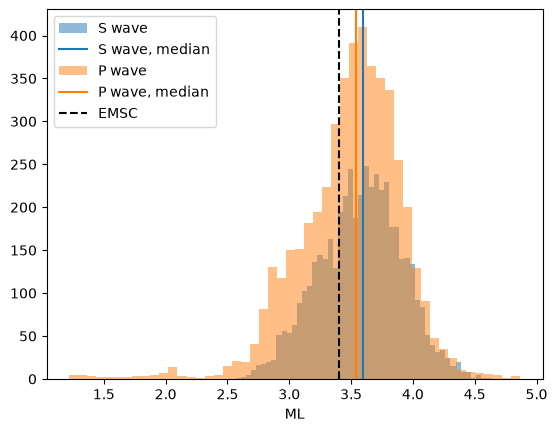

In [28]:
estimates = {
    "S wave": np.concatenate(list(magnitudes.values())),
    "P wave": np.concatenate([local_magnitude(6.0 * peaks_p[cable], distances[cable]) for cable in records]),
}
for (name, m), color in zip(estimates.items(), ["C0", "C1"]):
    plt.hist(m, bins=50, alpha=0.5, color=color, label=name)
    plt.axvline(np.median(m), color=color, label=f"{name}, median")
plt.axvline(3.4, color="k", linestyle="--", label="EMSC")
plt.xlabel("ML")
plt.legend()
pd.DataFrame({name: pd.Series(m).describe(percentiles=[0.05, 0.5, 0.95]) for name, m in estimates.items()})